In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

In [48]:
df = pd.read_csv('loan_guard_dataset.csv')

In [49]:
df.head()

,Customer_ID,Age,Gender,Marital_Status,Education_Level,Employment_Type,City_Tier,Monthly_Income,Monthly_Expenses,Savings_Balance,Existing_Loan_Amount,Credit_Card_Utilization,Debt_to_Income_Ratio,Number_of_Open_Accounts,Number_of_Credit_Cards,Loan_Amount_Requested,Loan_Tenure_Months,Loan_Purpose,Interest_Rate,EMI,EMI_to_Income_Ratio,Credit_Score,Previous_Defaults,Payment_Delay_Days,Credit_History_Years,Recent_Credit_Inquiries,Online_Application,App_Login_Frequency,Document_Verification_Score,Address_Stability_Years,Job_Stability_Years,Loan_Default
0,CUST00001,43,Male,Single,High School,Salaried,Tier 3,59340.0,28610,191571.0,0,74.8,0.087,4,3,181923.0,36,Home Renovation,7.50,5659,0.095,874.0,0,6,17.7,0,Yes,21,94.0,13.7,11.3,No
1,CUST00002,37,Male,Single,Graduate,Self-employed,Tier 3,36319.0,20934,154684.0,0,71.7,0.102,3,0,384578.0,24,Business,11.86,18078,0.498,721.0,0,12,4.4,0,No,14,85.0,0.0,2.7,No
2,CUST00003,44,Male,Divorced,High School,Salaried,Tier 1,73850.0,58910,47933.0,0,55.4,0.197,8,2,205141.0,36,Debt Consolidation,8.80,6504,0.088,NaN,0,8,18.9,1,Yes,19,92.1,8.3,4.4,No
3,CUST00004,53,Male,Married,Graduate,Salaried,Tier 3,133670.0,59521,352395.0,0,77.6,0.137,8,1,87070.0,24,Debt Consolidation,7.55,3920,0.029,NaN,0,1,27.4,2,No,10,75.0,27.0,23.0,No
4,CUST00005,36,Female,Single,Graduate,Salaried,Tier 3,51079.0,32733,120144.0,221301,54.4,0.416,6,0,106081.0,24,Vehicle,7.50,4774,0.093,811.0,0,11,4.4,2,No,11,86.2,1.3,4.4,No


In [139]:
df.shape

(10000, 32)

In [141]:
df = df.drop_duplicates()

In [51]:
df.isnull().sum()

Customer_ID                      0
Age                              0
Gender                           0
Marital_Status                   0
Education_Level                  0
Employment_Type                150
City_Tier                        0
Monthly_Income                 296
Monthly_Expenses                 0
Savings_Balance                776
Existing_Loan_Amount             0
Credit_Card_Utilization          0
Debt_to_Income_Ratio             0
Number_of_Open_Accounts          0
Number_of_Credit_Cards           0
Loan_Amount_Requested            0
Loan_Tenure_Months               0
Loan_Purpose                   100
Interest_Rate                    0
EMI                              0
EMI_to_Income_Ratio              0
Credit_Score                   500
Previous_Defaults                0
Payment_Delay_Days               0
Credit_History_Years             0
Recent_Credit_Inquiries          0
Online_Application               0
App_Login_Frequency              0
Document_Verificatio

In [52]:
df_cat = df.select_dtypes(exclude=np.number)
df_num = df.select_dtypes(include=np.number)

In [53]:
df_num.isnull().sum()
df_num['Monthly_Income'] = df_num['Monthly_Income'].fillna(df_num['Monthly_Income'].median())
df_num['Savings_Balance'] = df_num['Savings_Balance'].fillna(df_num['Savings_Balance'].median())
df_num['Credit_Score'] = df_num['Credit_Score'].fillna(df_num['Credit_Score'].median())
df_num['Document_Verification_Score'] = df_num['Document_Verification_Score'].fillna(df_num['Document_Verification_Score'].median())
df_num['Job_Stability_Years'] = df_num['Job_Stability_Years'].fillna(df_num['Job_Stability_Years'].median())

In [54]:
df_num.isnull().sum()

Age                            0
Monthly_Income                 0
Monthly_Expenses               0
Savings_Balance                0
Existing_Loan_Amount           0
Credit_Card_Utilization        0
Debt_to_Income_Ratio           0
Number_of_Open_Accounts        0
Number_of_Credit_Cards         0
Loan_Amount_Requested          0
Loan_Tenure_Months             0
Interest_Rate                  0
EMI                            0
EMI_to_Income_Ratio            0
Credit_Score                   0
Previous_Defaults              0
Payment_Delay_Days             0
Credit_History_Years           0
Recent_Credit_Inquiries        0
App_Login_Frequency            0
Document_Verification_Score    0
Address_Stability_Years        0
Job_Stability_Years            0
dtype: int64

In [55]:
df_cat.isnull().sum()

Customer_ID             0
Gender                  0
Marital_Status          0
Education_Level         0
Employment_Type       150
City_Tier               0
Loan_Purpose          100
Online_Application      0
Loan_Default            0
dtype: int64

In [56]:
df_cat['Employment_Type'] = df_cat['Employment_Type'].fillna(df_cat['Employment_Type'].mode()[0]) 
df_cat['Loan_Purpose'] = df_cat['Loan_Purpose'].fillna(df_cat['Loan_Purpose'].mode()[0]) 

In [57]:
df_cat.isnull().sum()

Customer_ID           0
Gender                0
Marital_Status        0
Education_Level       0
Employment_Type       0
City_Tier             0
Loan_Purpose          0
Online_Application    0
Loan_Default          0
dtype: int64

In [100]:
# Uni Variate Analysis

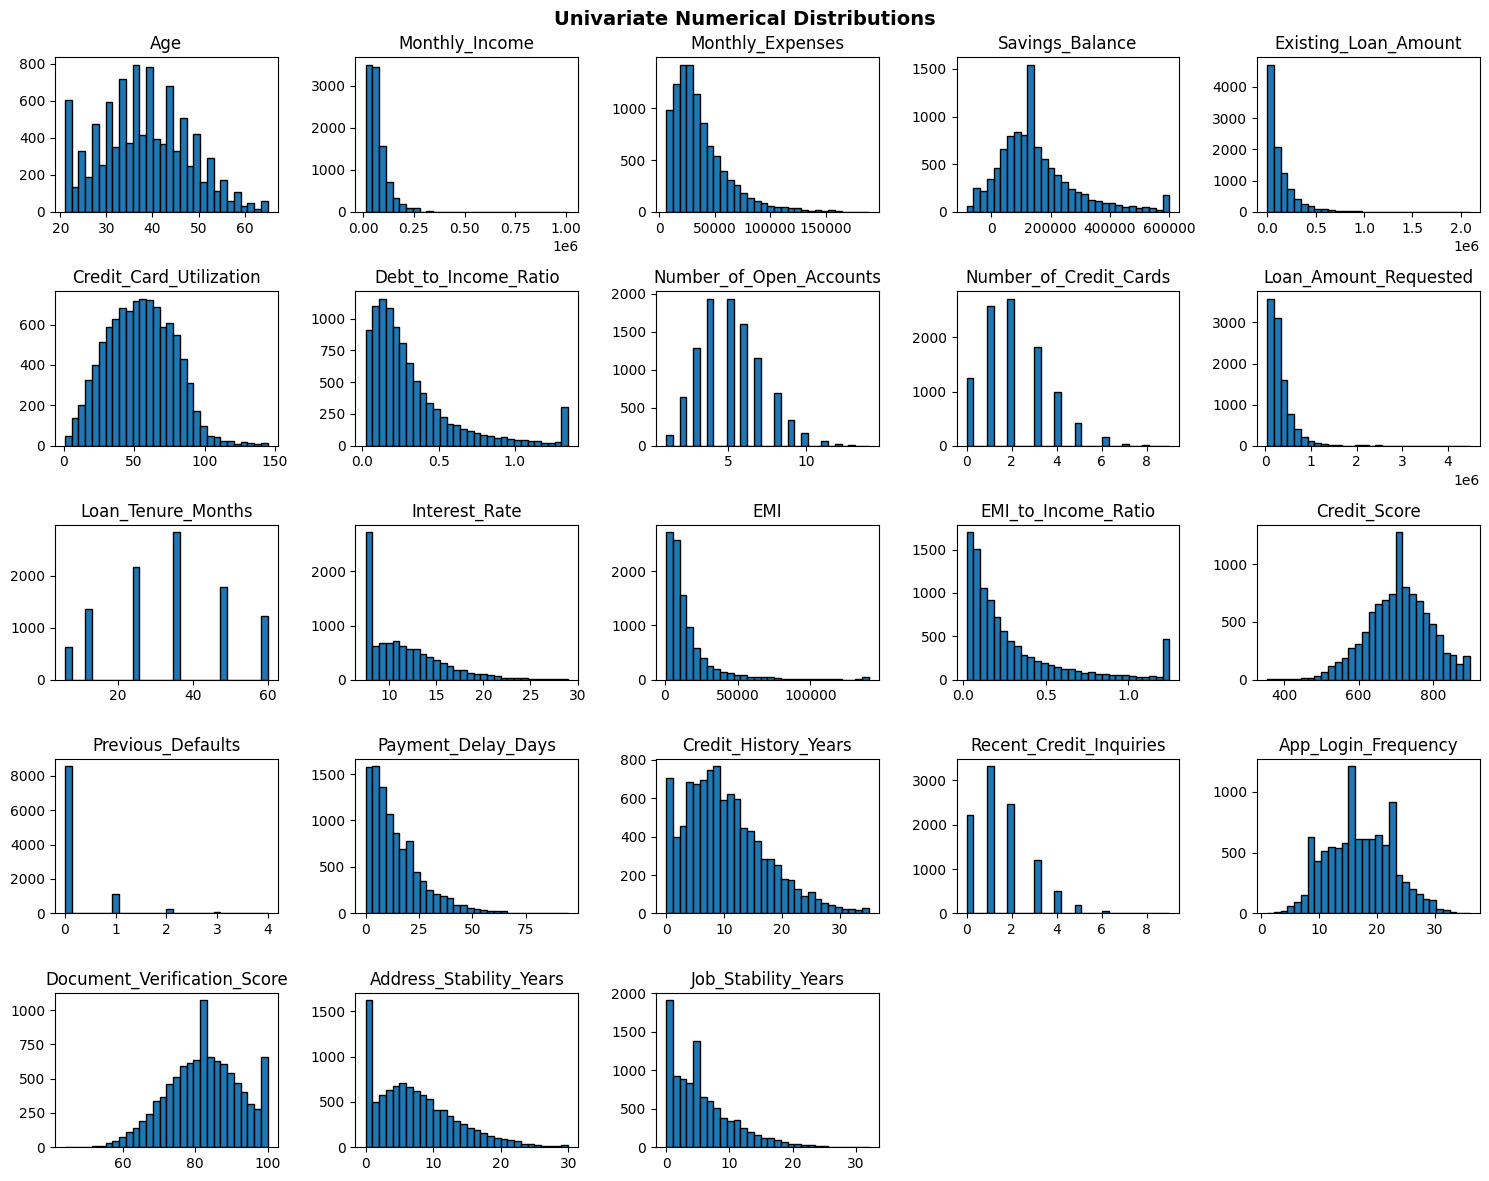

In [135]:
import matplotlib.pyplot as plt

df_num.hist(figsize=(15, 12), bins=30, edgecolor='black', grid=False)
plt.suptitle('Univariate Numerical Distributions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('Univariate Analysis - Numerical Variables Distribution.png')
plt.show()



In [105]:
df_cat.shape

(10000, 9)

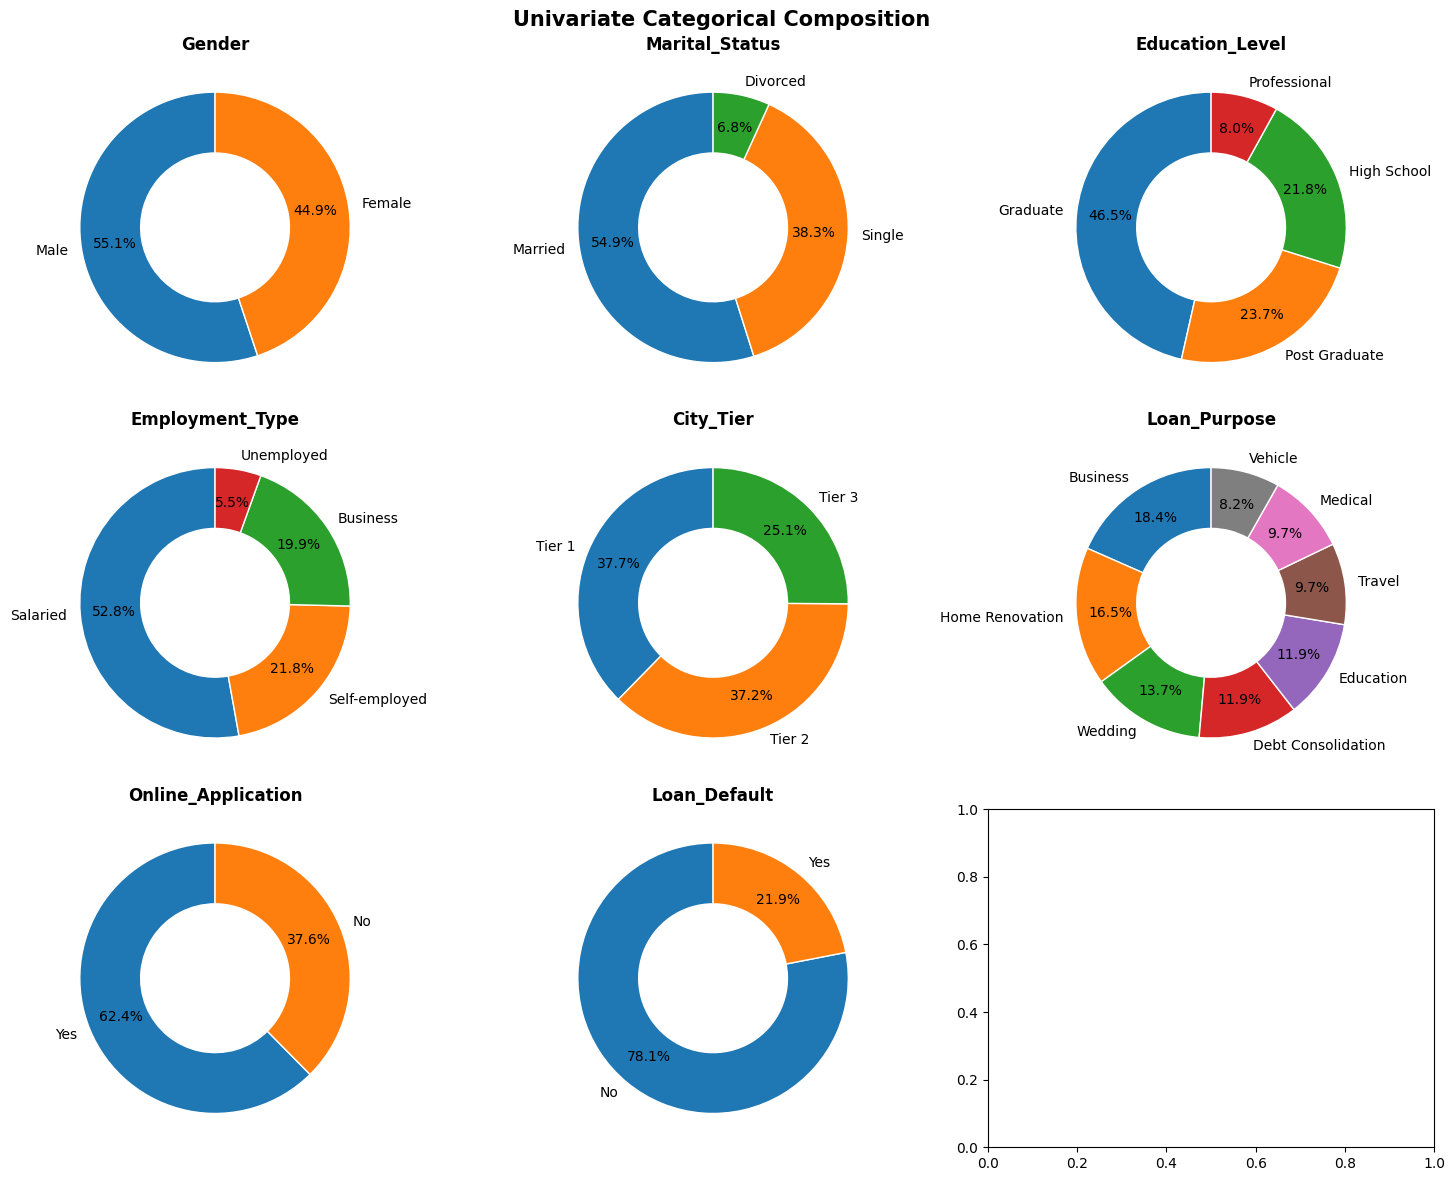

In [136]:
fig, axes = plt.subplots(3,3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(df_cat.drop(columns='Customer_ID').columns):
    counts = df_cat[col].value_counts()
    
    axes[i].pie(
        counts.values,
        labels=counts.index,
        autopct='%1.1f%%',
        startangle=90,
        pctdistance=0.75,
        wedgeprops=dict(width=0.45, edgecolor='white')  # Donut hole
    )
    axes[i].set_title(col, fontsize=12, fontweight='bold')

plt.suptitle('Univariate Categorical Composition', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('Univariate Analysis - Categorical Variables Composition.png')
plt.show()

In [118]:
df_num.columns

Index(['Age', 'Monthly_Income', 'Monthly_Expenses', 'Savings_Balance',
       'Existing_Loan_Amount', 'Credit_Card_Utilization',
       'Debt_to_Income_Ratio', 'Number_of_Open_Accounts',
       'Number_of_Credit_Cards', 'Loan_Amount_Requested', 'Loan_Tenure_Months',
       'Interest_Rate', 'EMI', 'EMI_to_Income_Ratio', 'Credit_Score',
       'Previous_Defaults', 'Payment_Delay_Days', 'Credit_History_Years',
       'Recent_Credit_Inquiries', 'App_Login_Frequency',
       'Document_Verification_Score', 'Address_Stability_Years',
       'Job_Stability_Years'],
      dtype='object')

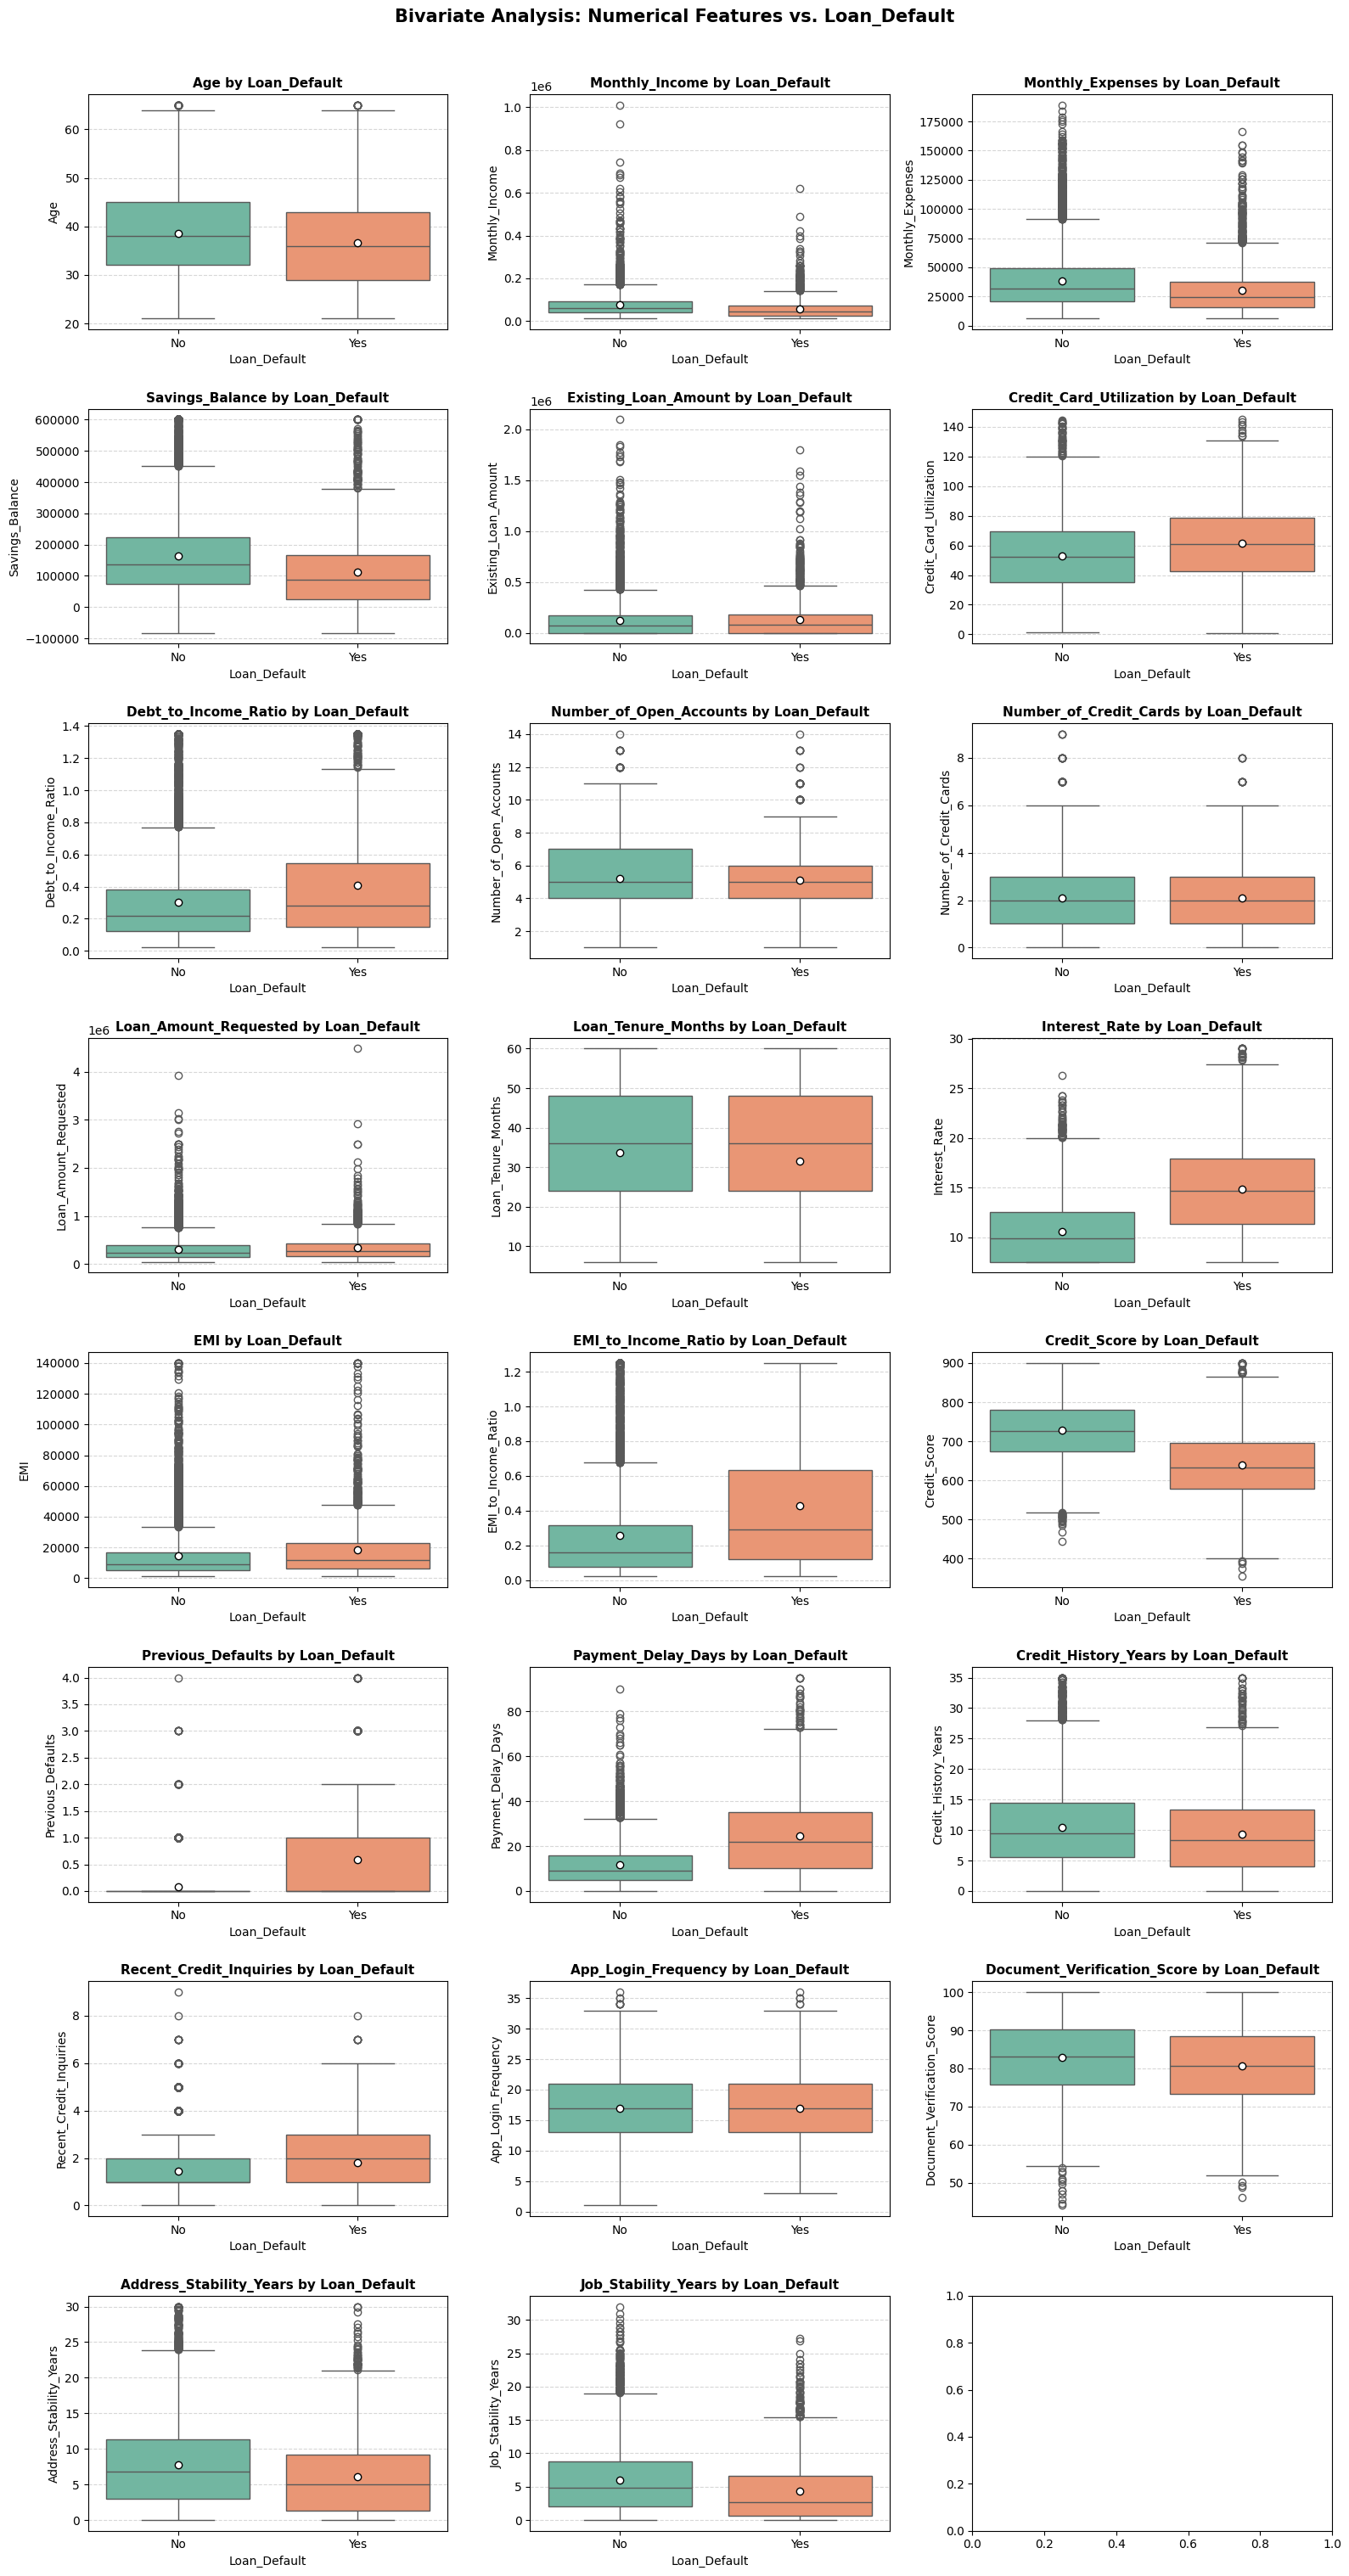

In [137]:
# BI Variate Analysis 
# Layout settings
import math
import warnings 
warnings.filterwarnings(action='ignore')
n_features = len(df_num.columns)
n_cols = 3
n_rows = math.ceil(n_features / n_cols)
target_col = 'Loan_Default'
fig, axes = plt.subplots(8, 3, figsize=(16, 30))
axes = axes.flatten()

for i, col in enumerate(df_num.columns):
    ax = axes[i]
    
    # Draw boxplot partitioned by target variable
    sns.boxplot(
        data=df,
        x=target_col,
        y=col,
        ax=ax,
        palette='Set2',
        showmeans=True,  # displays a marker for the mean
        meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": "6"}
    )
    
    ax.set_title(f'{col} by {target_col}', fontsize=11, fontweight='bold')
    ax.set_xlabel(target_col, fontsize=10)
    ax.set_ylabel(col, fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle(f'Bivariate Analysis: Numerical Features vs. {target_col}', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('BI-Variate Analysis - Numerical Variables vs Target Variable Distribution.png')
plt.show()

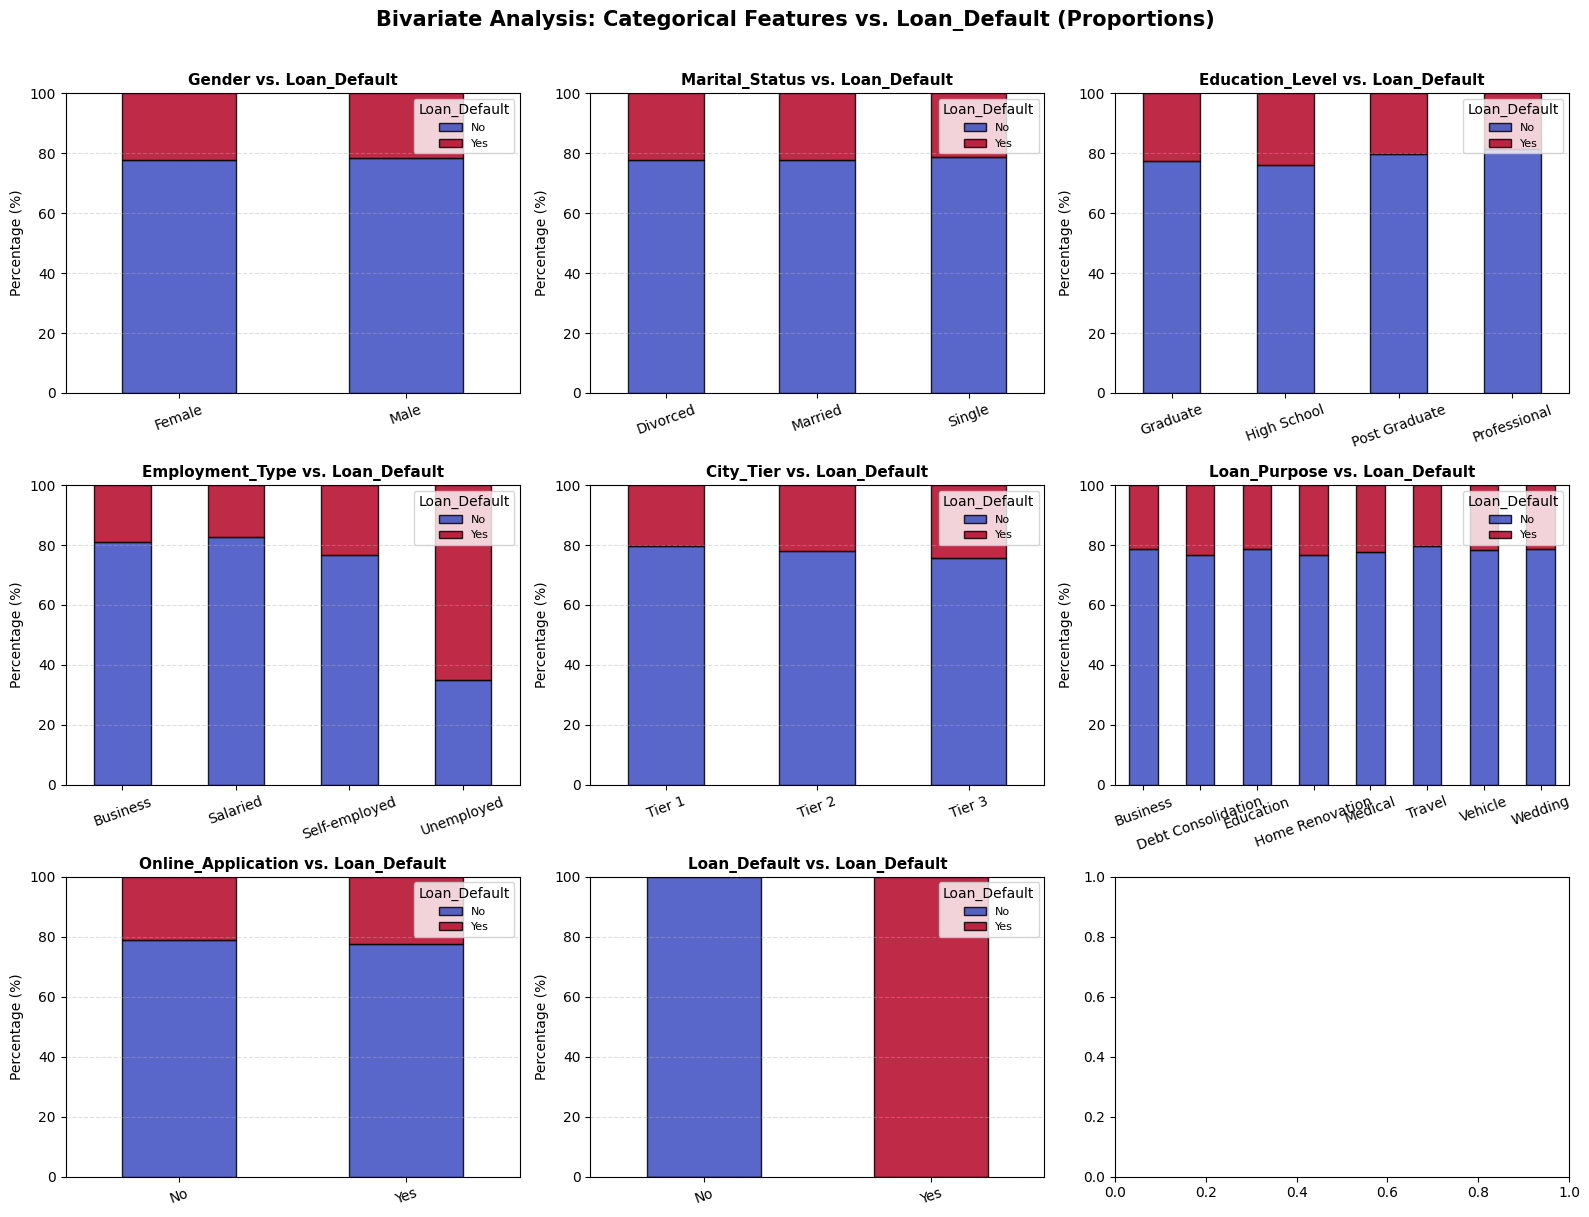

In [138]:
n_cat = len(df_cat.drop(columns='Customer_ID').columns)
n_cols = 3
n_rows = 3
target_col = 'Loan_Default'
fig, axes = plt.subplots(3,3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(df_cat.drop(columns='Customer_ID').columns):
    ax = axes[i]
    
    # Compute cross-tabulation normalized by row (proportions)
    cross_tab_prop = pd.crosstab(df[col], df[target_col], normalize='index') * 100
    
    # Plot 100% stacked bar chart
    cross_tab_prop.plot(
        kind='bar',
        stacked=True,
        ax=ax,
        colormap='coolwarm',
        edgecolor='black',
        alpha=0.85
    )
    
    ax.set_title(f'{col} vs. {target_col}', fontsize=11, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Percentage (%)', fontsize=10)
    ax.set_ylim(0, 100)
    ax.tick_params(axis='x', rotation=20)
    ax.legend(title=target_col, loc='upper right', fontsize=8)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.suptitle(f'Bivariate Analysis: Categorical Features vs. {target_col} (Proportions)', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('BI-Variate Analysis - Categorical Variables vs Target Variable Distribution.png')
plt.show()

In [117]:
# Encoding Categorical Data

In [59]:
df_cat_encoded = pd.get_dummies(df_cat.drop(columns=['Customer_ID','Loan_Default']),dtype='int',drop_first=True)

In [67]:
# Final_Df
final_df = pd.concat([df_num,df_cat_encoded,df[['Loan_Default']]],axis=1)
print(final_df.shape)
final_df.head()

(10000, 43)


,Age,Monthly_Income,Monthly_Expenses,Savings_Balance,Existing_Loan_Amount,Credit_Card_Utilization,Debt_to_Income_Ratio,Number_of_Open_Accounts,Number_of_Credit_Cards,Loan_Amount_Requested,Loan_Tenure_Months,Interest_Rate,EMI,EMI_to_Income_Ratio,Credit_Score,Previous_Defaults,Payment_Delay_Days,Credit_History_Years,Recent_Credit_Inquiries,App_Login_Frequency,Document_Verification_Score,Address_Stability_Years,Job_Stability_Years,Gender_Male,Marital_Status_Married,Marital_Status_Single,Education_Level_High School,Education_Level_Post Graduate,Education_Level_Professional,Employment_Type_Salaried,Employment_Type_Self-employed,Employment_Type_Unemployed,City_Tier_Tier 2,City_Tier_Tier 3,Loan_Purpose_Debt Consolidation,Loan_Purpose_Education,Loan_Purpose_Home Renovation,Loan_Purpose_Medical,Loan_Purpose_Travel,Loan_Purpose_Vehicle,Loan_Purpose_Wedding,Online_Application_Yes,Loan_Default
0,43,59340.0,28610,191571.0,0,74.8,0.087,4,3,181923.0,36,7.50,5659,0.095,874.0,0,6,17.7,0,21,94.0,13.7,11.3,1,0,1,1,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,No
1,37,36319.0,20934,154684.0,0,71.7,0.102,3,0,384578.0,24,11.86,18078,0.498,721.0,0,12,4.4,0,14,85.0,0.0,2.7,1,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,No
2,44,73850.0,58910,47933.0,0,55.4,0.197,8,2,205141.0,36,8.80,6504,0.088,711.0,0,8,18.9,1,19,92.1,8.3,4.4,1,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,No
3,53,133670.0,59521,352395.0,0,77.6,0.137,8,1,87070.0,24,7.55,3920,0.029,711.0,0,1,27.4,2,10,75.0,27.0,23.0,1,1,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,No
4,36,51079.0,32733,120144.0,221301,54.4,0.416,6,0,106081.0,24,7.50,4774,0.093,811.0,0,11,4.4,2,11,86.2,1.3,4.4,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,No


In [70]:
# Split the data 
X = final_df.drop(columns=['Loan_Default'])
y = final_df['Loan_Default']
xtrain,xtest,ytrain,ytest = train_test_split(X,y,train_size=0.8,test_size=0.2,random_state=100)

In [71]:
# Scaling

In [76]:
SS =StandardScaler()
xtrain_scaled =  pd.DataFrame(SS.fit_transform(xtrain),columns=xtrain.columns)
xtest_scaled = pd.DataFrame(SS.transform(xtest),columns=xtest.columns)

In [82]:
# Base Model 
LR_base = LogisticRegression(max_iter=1000)
LR_base.fit(xtrain,ytrain)
lr_base_pred = LR_base.predict(xtest)
print(classification_report(ytest,lr_base_pred))

              precision    recall  f1-score   support

          No       0.85      0.97      0.91      1572
         Yes       0.78      0.37      0.50       428

    accuracy                           0.84      2000
   macro avg       0.82      0.67      0.70      2000
weighted avg       0.83      0.84      0.82      2000



C:\Users\cenar\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [83]:
# Scaled Model 
LR_scaled = LogisticRegression(max_iter=1000)
LR_scaled.fit(xtrain_scaled,ytrain)
LR_scaled_pred = LR_scaled.predict(xtest_scaled)
print(classification_report(ytest,LR_scaled_pred))

              precision    recall  f1-score   support

          No       0.86      0.96      0.91      1572
         Yes       0.76      0.42      0.54       428

    accuracy                           0.85      2000
   macro avg       0.81      0.69      0.72      2000
weighted avg       0.84      0.85      0.83      2000



In [86]:
# Saving the Models as Pickle Files  
import pickle
model_filename = 'loan_default_model.pkl'

with open(model_filename, 'wb') as file:
    pickle.dump(LR_scaled, file)

In [92]:
# Loading back the saved model 
with open('loan_default_model.pkl', 'rb') as file:
    loaded_pickle_model = pickle.load(file)

# Example: make predictions with the loaded model
loaded_pickle_model.predict(xtest_scaled)

array(['Yes', 'No', 'No', ..., 'No', 'No', 'No'],
      shape=(2000,), dtype=object)

In [93]:
# Saving the Models as joblib file
import joblib
model_filename = 'loan_default_model.joblib'
joblib.dump(LR_scaled, model_filename)

['loan_default_model.joblib']

In [94]:
# Loading back the saved model
loaded_joblib_model = joblib.load('loan_default_model.joblib')

# Example: make predictions with the loaded model
loaded_joblib_model.predict(xtest_scaled)

array(['Yes', 'No', 'No', ..., 'No', 'No', 'No'],
      shape=(2000,), dtype=object)

#### Joblib is preferred for Scikit-Learn models because it efficiently handles large internal NumPy arrays with faster I/O and optional compression.

#### Pickle is Python's native standard-library tool designed to serialize general Python objects, but it is slower with large numerical matrices.

##### Syntax Convenience: joblib directly accepts a file path string (joblib.load('model.joblib')), whereas standard pickle requires manually managing file handles using open() in binary mode ('rb' / 'wb').